# Ejercicio 2

## 1. Descarga del Conjunto de Datos
Cargamos nuestro conjunto de datos, se comprueban las dimensiones del conjunto de datos y se visualizan las primeras filas para verificar la integridad de la información antes de proceder a la agregación de los datos por club.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")

# Carga de datos individuales
df = pd.read_csv('fifa_22_official_players_data.csv', low_memory=False)

print("--- 1. INFORMACIÓN A NIVEL DE JUGADOR INDIVIDUAL ---")
print(f"Dimensiones: {df.shape[0]} jugadores, {df.shape[1]} atributos.")
print(df[['overall', 'potential', 'age', 'value_eur']].describe())

--- 1. INFORMACIÓN A NIVEL DE JUGADOR INDIVIDUAL ---
Dimensiones: 19239 jugadores, 73 atributos.
            overall     potential           age     value_eur
count  19239.000000  19239.000000  19239.000000  1.916500e+04
mean      65.772182     71.079370     25.210822  2.850452e+06
std        6.880232      6.086213      4.748235  7.613700e+06
min       47.000000     49.000000     16.000000  9.000000e+03
25%       61.000000     67.000000     21.000000  4.750000e+05
50%       66.000000     71.000000     25.000000  9.750000e+05
75%       70.000000     75.000000     29.000000  2.000000e+06
max       93.000000     95.000000     54.000000  1.940000e+08


Tras ejecutar el código podemos observar un análisis detallado de las principales características cuantitativas a nivel de jugador individual. 


### 1.1 Exploración del Conjunto de Datos

#### 1.1.1. Agregación de Datos a Nivel de Club
Agrupamos por la variable categórica del club. Aplicamos funciones de agregación com media, la mediana para resumir las características físicas de la plantilla.
Para ello agrupamos los jugadores por `club_name` y calculamos las estadísticas generales de cada plantilla. Para cada club obtenmos la valoración media actual, la valoración central de los jugadores, su dispersión, velocidada....


In [4]:
# Agregación por club
club_agg = df.groupby('club_name').agg({
    'overall': ['mean', 'median', 'std'],
    'potential': ['mean', 'max', 'median'],
    'age': ['mean', 'std'],
    'pace': 'mean',
    'shooting': 'mean',
    'passing': 'mean',
    'dribbling': 'mean',
    'defending': 'mean',
    'physic': 'mean',
    'value_eur': 'sum' # Valor económico total de la plantilla
}).reset_index()

# Aplanar los nombres de las columnas multinivel
club_agg.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in club_agg.columns.values]

print("\n--- 2. INFORMACIÓN AGREGADA A NIVEL DE CLUB ---")
print(club_agg.head())
print(f"Total de clubes analizados: {club_agg.shape[0]}")


--- 2. INFORMACIÓN AGREGADA A NIVEL DE CLUB ---
               club_name  overall_mean  overall_median  overall_std  \
0  1. FC Heidenheim 1846     66.925926            68.0     4.480092   
1   1. FC Kaiserslautern     62.821429            63.5     3.559584   
2             1. FC Köln     69.161290            71.0     6.330333   
3        1. FC Magdeburg     62.107143            62.5     2.739820   
4         1. FC Nürnberg     65.689655            66.0     4.818887   

   potential_mean  potential_max  potential_median   age_mean   age_std  \
0       71.185185             76              71.0  24.666667  4.057282   
1       68.142857             76              67.0  24.285714  3.619465   
2       75.451613             82              76.0  24.225806  4.256052   
3       67.500000             73              68.0  23.750000  3.329164   
4       70.896552             79              71.0  24.689655  4.818887   

   pace_mean  shooting_mean  passing_mean  dribbling_mean  defending_mean

En los primeros resultados obtenidos podemos ver que el primer club tiene una valoración media de 71,19 y un valor aproximado de 42.5 millones de euros.

La desviación estándar permite conocer la homogeniedad de la plantilla, cuanto menor sea, más parecidos los jugadores entre si. Por ejemplo, el equipo 1 tiene un dispersión más reducida que la del equipo 2.

Esta transformación cambia el análisis de nivel individual a nivel de club y nos permite comparar la calidad media, el potencial y las características deportivas de cada club. 


#### 1.1.2 Análisis de Distribuciones
A continuación mediante el uso de histogramas evaluamos la forma de la distribución de los datos aplicada al potencial medio de los clubes para poder dividir los datos en tres clases distintas (Bajo, Medio, Alto)

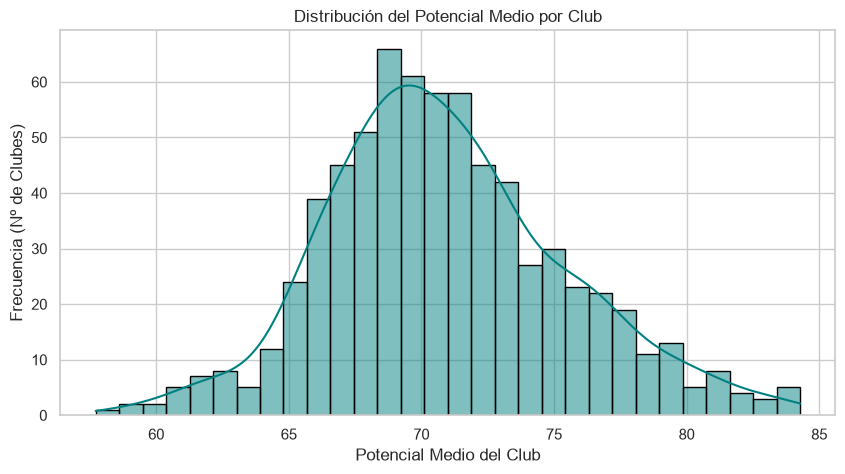

In [9]:
# 3. Distribución del potencial medio de los clubes
plt.figure(figsize=(10, 5))
sns.histplot(club_agg['potential_mean'], kde=True, bins=30, color='teal', edgecolor='black')
plt.title('Distribución del Potencial Medio por Club')
plt.xlabel('Potencial Medio del Club')
plt.ylabel('Frecuencia (Nº de Clubes)')
plt.show()

En cuanto al histograma generado la mayor concentración de clubes se encuentra entre un 65 y 75. Los clubes con un potencial medio más bajo aparecen en la parte izquierda mientras que los clubes con un potencial más alto a la derecha. La mayoría de los equipos presentan un potencial medio, mientras que solo una cantidad reducida alcanzan valores especialmente alto. Indicando que hay menos equipos con un potencial elevado. 

#### 1.1.3 Detección de valores Atipicos 
La detección de valores atípicos nos permite identificar observaciones que se alejan mucho del comportamiento habitual del conjunto de datos. Buscamos valores extremos como jugadores con valores económicos muy superiores al resto, datos poco representativos, valores nulos. La detección de estos valores evita que nuestro modelo se llene de ruido. 

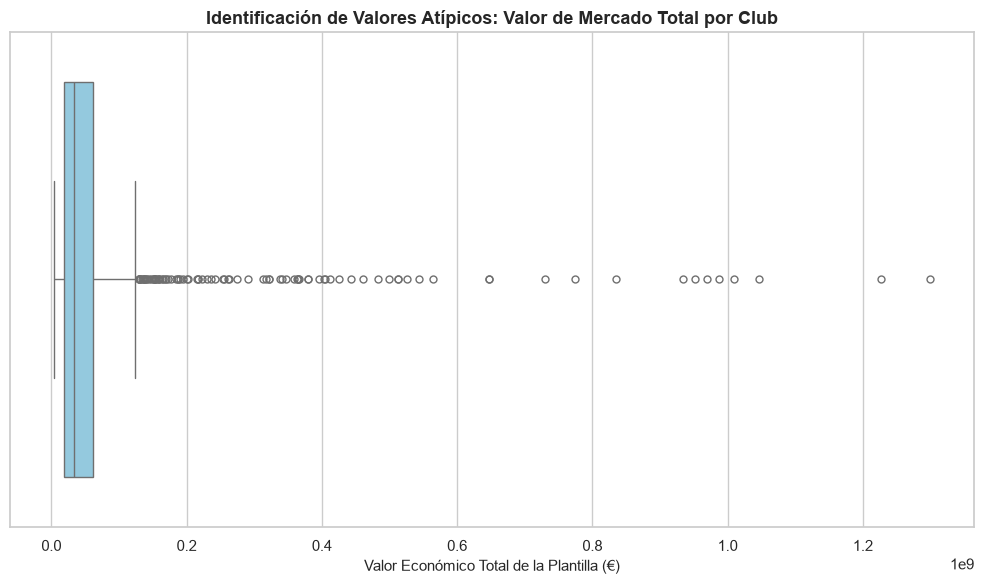

Límite inferior IQR: -46,050,000.00 €
Límite superior IQR: 126,510,000.00 €
Número de clubes identificados como outliers económicos: 90


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.figure(figsize=(10, 6))

# Generación del boxplot para la variable agregada 'value_sum' (Valor total de mercado del club)
sns.boxplot(x=club_agg['value_sum'], color='skyblue', fliersize=5)

plt.title('Identificación de Valores Atípicos: Valor de Mercado Total por Club', fontsize=13, fontweight='bold')
plt.xlabel('Valor Económico Total de la Plantilla (€)', fontsize=11)
plt.tight_layout()

# Guardar la figura para incluirla en el informe PDF final
plt.savefig('boxplot_outliers_clubes.png', dpi=300)
plt.show()

# Cálculo cuantitativo de los límites IQR para respaldar el gráfico
Q1 = club_agg['value_sum'].quantile(0.25)
Q3 = club_agg['value_sum'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = ((club_agg['value_sum'] < lower_bound) | (club_agg['value_sum'] > upper_bound)).sum()
print(f"Límite inferior IQR: {lower_bound:,.2f} €")
print(f"Límite superior IQR: {upper_bound:,.2f} €")
print(f"Número de clubes identificados como outliers económicos: {outliers_count}")

El elemento visual nos permite detectar clubes cuyo valor económico total se aleja del comportamiento habitual. El límite inferior es de −46.050.000 € y el superiror 26.510.000 €. Y se han identificado un total de 90 clubes con esos valores.

Como el valor económico de una plantilla no puede ser negativo, el límite inferiro no tiene una interpretación, por lo tanto los clubes con un límite superior se considerar atípicos. Con la ayuda de el diagrama de caja como elemento visual. Podemos ver que la mayoría de clubes se concentra en valores relativamente bajos, miertras que numeros puntos alejados representan los clubes con un valor económico demasiado alto. 



#### 1.1.4. Análisis de Correlaciones
Con la ayuda de un mapa de calor (Heat Map) estudiamos las relaciones entre las variables numéricas de nuestro dataset. 



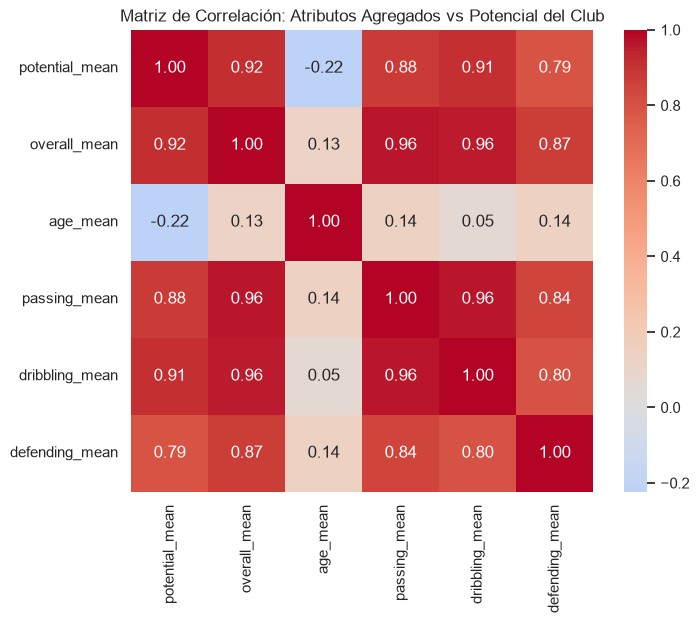

In [11]:
# Selección de variables agregadas numéricas para el análisis de correlación
cols_corr = ['potential_mean', 'overall_mean', 'age_mean', 'passing_mean', 'dribbling_mean', 'defending_mean']
matriz_corr = club_agg[cols_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', center=0, square=True, fmt='.2f')
plt.title('Matriz de Correlación: Atributos Agregados vs Potencial del Club')
plt.show()

La matriz de correlación generada, muestra una relacción muy positiva entre la calidad media de los clubes y sus características deportivas, Concretamente, el `overall_mean` con el `potencial_mean`, indicando que los clubes con una valoración media más alta suelen tener mayor potencial.
Las correlaciones más elevadas son entre `overall_mean` con `passing` y `dribbling` con un valor de 0.96. Esto significa que los clubes mejor valorados suelen tener jugadores con mejores capacidades de pase y regate. 

Finalmente la edad media presenta correlaciones debiles con el resto de variables. Por lo qye la edad no  parece ser un factor determinante para explicar la calidad o pontencial medio del club. 

### 1.2 Preprocesamiento y Transformación de Datos

En este apartado preparamos el dataset para que pueda ser analizado correctamente. Se revisan los tipos de datos se localizan valores nulos, se transforman algunos datos... Además se estudia el contenido y comportamiento del dataser. Analizando su tamaño, las variables disponinles...

#### 1.2.1 Agregar los atributos individuales de los jugadores por club 

Para ello vamos a agrupar el conjunto de datos por el nombre del equipo y aplicar funciones como la media, la mediana y la desviación estandar.

In [12]:
import pandas as pd
import numpy as np

# 1. Agrupar los datos por club y calcular estadísticos agregados
club_agg = df.groupby('club_name').agg({
    # Valoración y Potencial (Media, Máximo y Mediana)
    'overall': ['mean', 'median', 'std'],
    'potential': ['mean', 'max', 'std'],
    
    # Perfil Demográfico (Edad media y desviación para ver si hay mezcla de jóvenes y veteranos)
    'age': ['mean', 'std'],
    
    # Atributos Físicos, Técnicos y Mentales (Medias de la plantilla)
    'pace': 'mean',
    'shooting': 'mean',
    'passing': 'mean',
    'dribbling': 'mean',
    'defending': 'mean',
    'physic': 'mean',
    
    # Aspectos económicos (Suma total del valor de mercado y salarios de la plantilla)
    'value_eur': 'sum',
    'wage_eur': 'sum',
    
    # Recuento de jugadores en la plantilla del club
    'sofifa_id': 'count'
}).reset_index()

# 2. Aplanar el índice multinivel generado en las columnas
club_agg.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in club_agg.columns.values]

# Renombrar la columna de conteo para mayor claridad
club_agg.rename(columns={'sofifa_id_count': 'quad_size'}, inplace=True)

print(f"Dimensiones del dataset agregado por club: {club_agg.shape[0]} clubes y {club_agg.shape[1]} atributos.")
club_agg.head(3)

Dimensiones del dataset agregado por club: 701 clubes y 18 atributos.


,club_name,overall_mean,overall_median,overall_std,potential_mean,potential_max,potential_std,age_mean,age_std,pace_mean,shooting_mean,passing_mean,dribbling_mean,defending_mean,physic_mean,value_eur_sum,wage_eur_sum,quad_size
0,1. FC Heidenheim 1846,66.925926,68.0,4.480092,71.185185,76,3.351659,24.666667,4.057282,68.041667,53.833333,57.083333,62.583333,53.416667,68.166667,42500000.0,249000.0,27
1,1. FC Kaiserslautern,62.821429,63.5,3.559584,68.142857,76,3.545621,24.285714,3.619465,69.960000,49.520000,53.120000,60.000000,45.720000,64.280000,21280000.0,42800.0,28
2,1. FC Köln,69.161290,71.0,6.330333,75.451613,82,4.015293,24.225806,4.256052,66.703704,54.925926,61.925926,67.370370,56.148148,67.111111,101995000.0,432050.0,31


La desviación estándar permite conocer la variedad interna de cada plantilla. Por ejemplo el equipo 2 presenta un desviación de 6,33 lo que indica mayor diferencia de nivel entre sus jugadores mientras que el equipo 1 tiene una desviación menor de 3,56

La agregación permite comparar los clubes según las variables numéricas. 

#### 1.2.2 Clasificación de Variables